# NO$_2$ response to rain after dry conditions composite both yrs

Grid cell events with a 7-day dry period receiving < 2.5 mm cumulative precipitation, followed by an hourly precipitation event > 5 mm h$^{-1}$.

Hours removed by the IMERG quality/phase filters are treated as missing, not 0 mm: the 7-day total is the mean of the valid hours × 168 h,
and a week needs ≥ `MIN_VALID_FRAC` valid hours to count. NO$_2$ is normalized to its preceding 7-day background at the event time and composited ±7 days.

`NO2_HOUR_MIN = 10` keeps only NO$_2$ observed at or after 10:00 local

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

DIR = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets'
FILES = {2024: f'{DIR}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_2024.parquet',
         2025: f'{DIR}/lowCF_filtered_merged_with_incdec_MCD12Q1mask_2025.parquet'}

DRY_DAYS, DRY_MM, RAIN_MM = 7, 2.5, 5
MIN_VALID_FRAC = 0.6    
BG_DAYS, BG_MIN_OBS = 7, 12
HALF = 7 * 24
NO2_HOUR_MIN = 10       
EVENT_HOUR_MIN = None 

## Detect events

In [2]:
def detect_pulses(df, dry_days=7, dry_sum_thresh_mm=2.5, rain_hourly_thresh=5, min_valid_frac=0.5):
    d = df.copy()
    d['datetime'] = pd.to_datetime(d['datetime'])
    d = d.sort_values(['grid_lat', 'grid_lon', 'datetime'])
    d['h_precip_mm'] = pd.to_numeric(d['h_precip_mm'], errors='coerce')  

    dry_hours = int(dry_days * 24) # days to hrs
    out = []

    for (lat, lon), g in d.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index() 
        p = g['h_precip_mm']

        n_valid = p.notna().rolling(dry_hours, min_periods=dry_hours).sum() 
        roll_sum = p.rolling(dry_hours, min_periods=1).mean() * dry_hours       
        roll_sum = roll_sum.where(n_valid >= min_valid_frac * dry_hours)
        g['dry_window'] = (roll_sum < dry_sum_thresh_mm).astype('boolean') 
        prev_dry = g['dry_window'].shift(1, fill_value=False) #same

        g['pulse_start'] = ((p > rain_hourly_thresh) & prev_dry).astype('boolean')
        out.append(g.reset_index())

    return pd.concat(out, ignore_index=True)

def composite(table, z=1.96):
    mean, std, count = table.mean(), table.std(), table.count() 
    sem = std / np.sqrt(count.clip(lower=1))
    return pd.DataFrame({'mean': mean, 'lo': mean - z * sem, 'hi': mean + z * sem, 'count': count})

## Detect events, background and ±7-day windows for each year, then pool

In [3]:
def run_year(file):
    df = pd.read_parquet(file, columns=['grid_lat', 'grid_lon', 'datetime', 'datetime_local', 'h_precip_mm', 'no2_mean', 'WFPS_c'])
    pulses = detect_pulses(df, dry_days=DRY_DAYS, dry_sum_thresh_mm=DRY_MM, rain_hourly_thresh=RAIN_MM, min_valid_frac=MIN_VALID_FRAC)
    del df
    n_pulses = int(pulses['pulse_start'].sum())

    times = pd.date_range(pulses['datetime'].min(), pulses['datetime'].max(), freq='h')
    cell_id = pulses.groupby(['grid_lat', 'grid_lon'], sort=False).ngroup().to_numpy()
    ti = times.get_indexer(pulses['datetime'])
    T, C = len(times), cell_id.max() + 1
    def to_mat(col):
        M = np.full((T, C), np.nan, np.float32)
        M[ti, cell_id] = pd.to_numeric(pulses[col], errors='coerce').to_numpy(np.float32)
        return M
    P, NO2, WFPS = to_mat('h_precip_mm'), to_mat('no2_mean'), to_mat('WFPS_c')

    LHR = np.full((T, C), np.nan, np.float32)
    LHR[ti, cell_id] = pd.to_datetime(pulses['datetime_local']).dt.hour.to_numpy(np.float32)
    if NO2_HOUR_MIN is not None:
        NO2[~(LHR >= NO2_HOUR_MIN)] = np.nan


    # 7-day NO2 background 
    n = BG_DAYS * 24
    no2 = pd.DataFrame(NO2)
    BG = no2.rolling(n, min_periods=1).mean().shift(1).where(no2.rolling(n, min_periods=1).count().shift(1) >= BG_MIN_OBS).to_numpy()

    # events with a valid background
    m = pulses['pulse_start'].to_numpy(bool)
    events = pd.DataFrame({'t': ti[m], 'c': cell_id[m]})
    events['bg0'] = BG[events['t'], events['c']]
    n_all = len(events)
    events = events[events['bg0'].notna() & (events['bg0'] != 0)].reset_index(drop=True)

    if EVENT_HOUR_MIN is not None:
        events = events[LHR[events['t'], events['c']] >= EVENT_HOUR_MIN].reset_index(drop=True)

    def event_windows(X):
        table = pd.DataFrame(np.nan, index=events.index, columns=lags)
        for i, ev in events.iterrows():
            t, c = int(ev['t']), int(ev['c'])
            start, end = max(t - HALF, 0), min(t + HALF, T - 1)
            table.loc[i, start - t:end - t] = X[start:end + 1, c]
        return table

    print(f'{file.split("/")[-1]}: {n_pulses:,} pulses detected, {len(events):,} retained after normalization')
    meta = events.assign(time=times[events['t'].to_numpy()])          # event time (UTC) for diagnostics
    return {'precip': event_windows(P), 'wfps': event_windows(WFPS),
            'no2': event_windows(NO2).div(events['bg0'], axis=0), 'meta': meta}

lags = np.arange(-HALF, HALF + 1)
tabs = {y: run_year(f) for y, f in FILES.items()}

# pool all events from both years, every event weighted equally
comp = {k: composite(pd.concat([tabs[y][k] for y in tabs], ignore_index=True)) for k in ['precip', 'wfps', 'no2']}
x = lags
print(f"pooled: {sum(len(tabs[y]['no2']) for y in tabs):,} events")

lowCF_filtered_merged_with_incdec_MCD12Q1mask_2024.parquet: 3,437 pulses detected, 3,426 retained after normalization
lowCF_filtered_merged_with_incdec_MCD12Q1mask_2025.parquet: 4,500 pulses detected, 4,323 retained after normalization
pooled: 7,749 events


## Figure

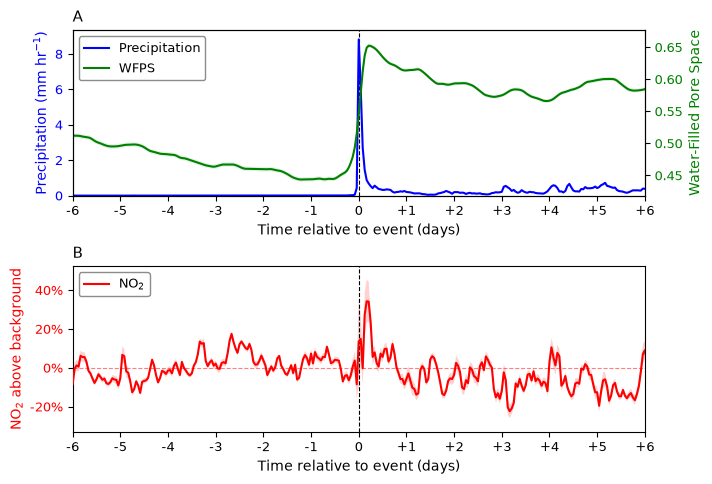

In [4]:
cm = 1 / 2.54
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 11, 'xtick.labelsize': 9,
                     'ytick.labelsize': 9, 'legend.fontsize': 9, 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'svg.fonttype': 'none', 'savefig.dpi': 600})

fig, (ax_p, ax_n) = plt.subplots(2, 1, figsize=(17.8 * cm, 12 * cm), constrained_layout=True)
ticks = range(-144, 145, 24)

def band(ax, c, color, alpha, **kw):
    line, = ax.plot(x, c['mean'], lw=1.5, color=color, **kw)
    ax.fill_between(x, c['lo'], c['hi'], color=color, alpha=alpha, edgecolor='none', zorder=line.get_zorder() - 1)
    return line

def pad(ax, c):
    lo, hi = c['lo'].min(), c['hi'].max(); p = (hi - lo) * 0.1
    ax.set_ylim(lo - p, hi + p)

#precipitation + WFPS
p_line = band(ax_p, comp['precip'], 'blue', 0.18, zorder=5)
ax_p.set_ylabel('Precipitation (mm hr$^{-1}$)', color='blue'); ax_p.tick_params(axis='y', labelcolor='blue'); ax_p.set_ylim(bottom=0)
ax_w = ax_p.twinx()
w_line = band(ax_w, comp['wfps'], 'green', 0.10, zorder=2)
ax_w.set_ylabel('Water-Filled Pore Space', color='green'); ax_w.tick_params(axis='y', labelcolor='green'); pad(ax_w, comp['wfps'])
ax_p.legend([p_line, w_line], ['Precipitation', 'WFPS'], loc='upper left', facecolor='white', edgecolor='gray', framealpha=0.9)

#NO2 above background
n_line = band(ax_n, comp['no2'], 'red', 0.18, zorder=3)
ax_n.axhline(1.0, ls='--', color='red', lw=0.8, alpha=0.5, zorder=1)
ax_n.set_ylabel('NO$_2$ above background', color='red'); ax_n.tick_params(axis='y', labelcolor='red')
ax_n.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%'))
pad(ax_n, comp['no2'])
ax_n.legend([n_line], ['NO$_2$'], loc='upper left', facecolor='white', edgecolor='gray', framealpha=0.9)


for ax, l in [(ax_p, 'A'), (ax_n, 'B')]:
    ax.axvline(0, ls='--', color='black', lw=0.8)
    ax.set_xlim(-144, 144); ax.set_xticks(ticks)
    ax.set_xticklabels([f'{h // 24:+d}' if h else '0' for h in ticks])
    ax.set_xlabel('Time relative to event (days)'); ax.set_title(l, loc='left')

tag = f"NO2ge{NO2_HOUR_MIN}" if NO2_HOUR_MIN is not None else "allhours"
fig.savefig(f"Composite evolution_{'-'.join(map(str, FILES))}_{tag}.pdf")
plt.show()